# 人口データから考えるイベント開催地域

**氏名：原田琉太**  
**依頼元：イベント企画会社（架空）**  
**読み手：イベント企画担当の上司**  
**調べたい問い：人口が多い都道府県はどこか。また、高齢者の割合が高い地域とはどう違うのか。**

イベントの開催候補を考えるため、授業で配布された `japan.csv` の47都道府県のデータを調べます。

## 1．データの読み込みと確認

授業で紹介された `csv.DictReader` を使ってCSVを読み込みます。都道府県の数と、最初のデータを表示して確認します。

In [1]:
import csv
import matplotlib.pyplot as plt

with open("japan.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

print("都道府県数：", len(data))
print("最初のデータ：", data[0]["都道府県"], data[0]["総人口"], "人")

都道府県数： 47
最初のデータ： 北海道 5140000 人


## 2．人口上位5都道府県のグラフ

総人口を数値にして大きい順に並べ、上位5都道府県を棒グラフで比較します。単位は百万人です。

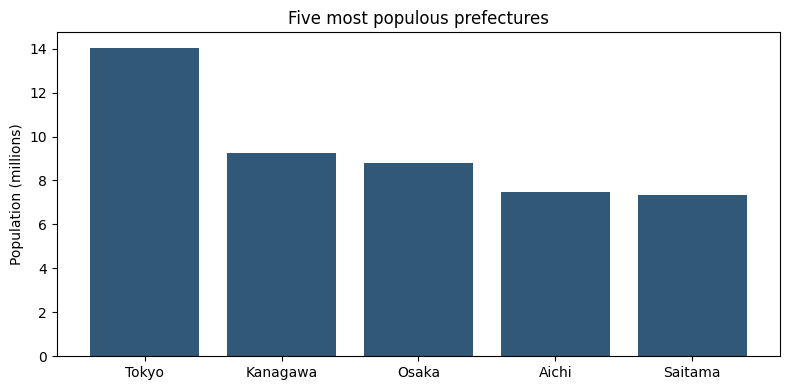

In [2]:
top5 = sorted(data, key=lambda row: int(row["総人口"]), reverse=True)[:5]
names = [row["Prefecture"] for row in top5]
population = [int(row["総人口"]) / 1000000 for row in top5]

plt.figure(figsize=(8, 4))
plt.bar(names, population, color="#315876")
plt.ylabel("Population (millions)")
plt.title("Five most populous prefectures")
plt.tight_layout()
plt.show()

## 3．人口ランキングを数字でも表示

グラフだけでは正確な人数が分かりにくいため、`while` 文を使って順位と人口を表示します。

In [3]:
rank = 0
print("【総人口ランキング TOP5】")
while rank < len(top5):
    row = top5[rank]
    print("{}位：{}　{}人".format(rank + 1, row["都道府県"], int(row["総人口"])))
    rank += 1

【総人口ランキング TOP5】
1位：東京都　14038000人
2位：神奈川県　9232000人
3位：大阪府　8782000人
4位：愛知県　7495000人
5位：埼玉県　7337000人


## 4．高齢者の割合が高い都道府県

65歳以上人口を総人口で割って割合を求め、割合の高い上位5都道府県を横棒グラフにします。人数ではなく割合で比較することがポイントです。

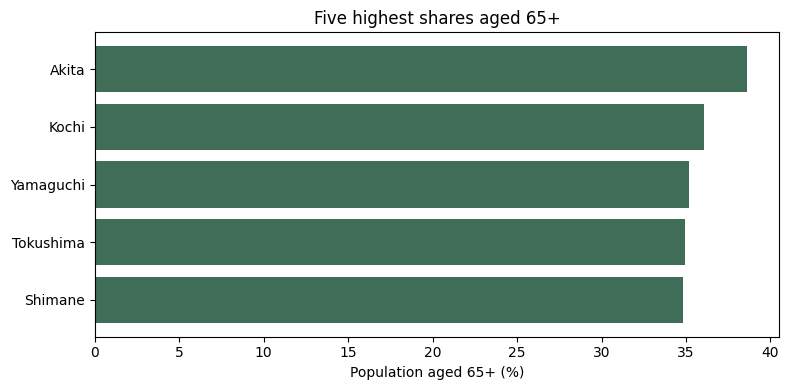

In [4]:
senior_top5 = sorted(data,
    key=lambda row: int(row["65歳以上人口"]) / int(row["総人口"]),
    reverse=True)[:5]
names = [row["Prefecture"] for row in senior_top5]
shares = [int(row["65歳以上人口"]) / int(row["総人口"]) * 100 for row in senior_top5]

plt.figure(figsize=(8, 4))
plt.barh(names, shares, color="#3f6d57")
plt.gca().invert_yaxis()
plt.xlabel("Population aged 65+ (%)")
plt.title("Five highest shares aged 65+")
plt.tight_layout()
plt.show()

## 5．高齢者割合ランキング

こちらも `while` 文を使って順位と割合を表示します。

In [5]:
rank = 0
print("【65歳以上人口の割合ランキング TOP5】")
while rank < len(senior_top5):
    row = senior_top5[rank]
    share = int(row["65歳以上人口"]) / int(row["総人口"]) * 100
    print("{}位：{}　{:.1f}%".format(rank + 1, row["都道府県"], share))
    rank += 1

【65歳以上人口の割合ランキング TOP5】
1位：秋田県　38.6%
2位：高知県　36.1%
3位：山口県　35.2%
4位：徳島県　34.9%
5位：島根県　34.8%


## 6．人口200万人以上と300万人以上の地域を比較

先週の分析も利用し、`for` 文と `if` 文で条件に合う都道府県を数えます。

In [6]:
count200 = 0
count300 = 0

for row in data:
    population = int(row["総人口"])
    if population >= 2000000:
        count200 += 1
    if population >= 3000000:
        count300 += 1

print("人口200万人以上：{}都道府県".format(count200))
print("人口300万人以上：{}都道府県".format(count300))

人口200万人以上：16都道府県
人口300万人以上：10都道府県


## 7．わかったことと組織への提案

総人口のランキングでは東京都が1位でした。一方、高齢者の割合が高い地域のランキングは、人口が多い地域のランキングとは異なりました。人口が200万人以上の都道府県は16、300万人以上は10でした。

イベント企画会社には、**大規模なイベントの候補地を考えるときは人口の多い地域を参考にし、高齢者向けイベントを考えるときは高齢者の割合も確認すること**を提案します。ただし、人口だけでイベントの参加人数は決まりません。会場への交通アクセスや実際の参加希望者も調べる必要があります。

**先週からの改善点：** 人口の条件による集計に加え、人口と高齢者割合の上位5都道府県をグラフと順位付きランキングで示し、比較しやすくしました。

**データの出典：** 授業配布の `japan.csv`（47都道府県）。人口の単位は人、高齢者割合の単位は%。元の統計の調査年を確認できないため、現在の人口を示すとは限りません。

**生成AIの利用：** コードの整理、ランキング表示の追加、文章の作成補助に利用しました。